# List-aware models

Sandbox for the list-aware track.

**Train** is every sale in `listings` before December 2025. **Validation** is the sales from December 2025 through May 2026. Those months still have a sold price. `test_list_aware` is the submission file: it has no sold price, and this notebook does not use it.

This is one time split, for choosing a model. `python run.py validate` refits every month from December 2025 through May 2026. That is the number to report once a model moves into `models.py`.

The list-price baseline on this same validation window is the bar. Errors are percentages of the sold price. MdAPE is the median absolute percentage error. MAPE is the mean. The median signed error is positive when the model predicts high.

In [1]:
import os
import sys

if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, os.getcwd())

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from scipy import stats
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.statespace.sarimax import SARIMAX

import data
from features import square_feet

scores = []


def percentage_scores(predicted, sold):
    signed = 100 * (np.asarray(predicted) - np.asarray(sold)) / np.asarray(sold)
    absolute = np.abs(signed)
    return {
        "MdAPE": round(float(np.median(absolute)), 2),
        "MAPE": round(float(np.mean(absolute)), 2),
        "median_signed_error": round(float(np.median(signed)), 2),
    }


def add_score(name, predicted, sold):
    row = {"model": name, **percentage_scores(predicted, sold)}
    scores.append(row)
    print(f"{name}: MdAPE {row['MdAPE']:.2f}%, MAPE {row['MAPE']:.2f}%, median signed error {row['median_signed_error']:+.2f}%")
    return row

## Split and the list-price baseline

The baseline predicts that every home sells for its list price.

In [2]:
listings = data.load("listings").copy()
listings["square_feet"] = square_feet(listings["house_area"])

holdout_start = pd.Timestamp("2025-12-01")
train = listings[listings["date_sold"] < holdout_start].copy()
valid = listings[listings["date_sold"] >= holdout_start].copy()
print(f"Train: {len(train):,} sales, {train['date_sold'].min():%Y-%m-%d} to {train['date_sold'].max():%Y-%m-%d}")
print(f"Validation: {len(valid):,} sales, {valid['date_sold'].min():%Y-%m-%d} to {valid['date_sold'].max():%Y-%m-%d}")

add_score("List price", valid["list_price"], valid["sold_price"])

Train: 139,931 sales, 2021-01-01 to 2025-11-30
Validation: 10,069 sales, 2025-12-01 to 2026-05-31
List price: MdAPE 7.26%, MAPE 8.09%, median signed error +5.68%


{'model': 'List price',
 'MdAPE': 7.26,
 'MAPE': 8.09,
 'median_signed_error': 5.68}

## Shared numeric design

The skew table is in `list_aware_eda.ipynb`. Prices and square feet are logged. Lot front is logged, and homes with no lot keep a missing indicator instead of a filled-in frontage. Lot depth, the room and parking counts, and the coordinates stay as they are.

`numeric_design` is the matrix both models use. Nothing in it is estimated from the validation months.

In [3]:
def numeric_design(frame):
    missing_lot = frame["lot_front"].isna()
    X = pd.DataFrame(index=frame.index)
    X["log_list_price"] = np.log(frame["list_price"])
    X["log_square_feet"] = np.log(frame["square_feet"])
    X["lot_missing"] = missing_lot.astype(float)
    # log(1) = 0 on a missing lot, so the frontage slope is identified from homes that have one.
    X["log_lot_front"] = np.log(frame["lot_front"].where(~missing_lot, 1.0))
    X["lot_depth"] = frame["lot_depth"].fillna(0.0)
    for column in ["bedrooms", "washrooms", "parking_total", "garage", "latitude", "longitude"]:
        X[column] = frame[column].astype(float)
    return X


train_X = sm.add_constant(numeric_design(train), has_constant="add")
valid_X = sm.add_constant(numeric_design(valid), has_constant="add")
train_X.head()

,const,log_list_price,log_square_feet,lot_missing,log_lot_front,lot_depth,bedrooms,washrooms,parking_total,garage,latitude,longitude
0,1.0,12.824496,6.432940,1.0,0.0,0.0,1.0,1.0,0.0,0.0,43.602039,-79.261184
1,1.0,13.297660,6.475433,1.0,0.0,0.0,2.0,1.0,0.0,0.0,43.695388,-79.510865
2,1.0,13.043753,6.907255,1.0,0.0,0.0,2.0,1.0,1.0,0.0,43.740512,-79.386216
3,1.0,13.170963,6.775366,1.0,0.0,0.0,1.0,1.0,1.0,0.0,43.643774,-79.470180
4,1.0,13.232652,6.242223,1.0,0.0,0.0,1.0,1.0,1.0,0.0,43.696172,-79.274137


## V1: Regression on the numeric columns

Two ordinary least-squares fits, same columns, so the transform is the only difference.

- **Untransformed.** Sold price on the raw numbers. Lot front and lot depth are 0 when the lot is missing.
- **Log scale.** Log sold price on `numeric_design`. Predictions are exponentiated back to dollars.

Each table is the coefficient, its standard error, the t statistic, and the p-value. Training uses about 140,000 sales, so a very small coefficient can still have a tiny p-value. Read the coefficient size next to the star.

The normality assumption is about the residuals. The plots are a sample of 3,000 residuals against a normal line. With this many rows, a formal normality test rejects even small departures, so the residual skew is the comparison to read.

OLS, untransformed: MdAPE 6.86%, MAPE 7.83%, median signed error +5.60%
OLS, log scale: MdAPE 7.13%, MAPE 8.05%, median signed error +5.95%
Residual skew, untransformed: 2.56
Residual skew, log scale: 0.72
Untransformed regression. Coefficients are in dollars of sold price.


<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:             sold_price   R-squared:                       0.973
Model:                            OLS   Adj. R-squared:                  0.973
Method:                 Least Squares   F-statistic:                 5.067e+05
Date:                Thu, 29 Oct 2026   Prob (F-statistic):               0.00
Time:                        17:06:27   Log-Likelihood:            -1.8493e+06
No. Observations:              139931   AIC:                         3.699e+06
Df Residuals:                  139920   BIC:                         3.699e+06
Df Model:                          10                                         
Covariance Type:            nonrobust                                         
=================================================================================
                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
const         -1.482e+06   4.23e+05     -3.503      0.000   -2.31e+06   -6.53e+05
list_price        0.9431      0.001   1346.071      0.000       0.942       0.944
square_feet      34.7922      0.816     42.631      0.000      33.193      36.392
lot_front        85.3364     34.950      2.442      0.015      16.836     153.837
lot_depth       280.3863     11.864     23.633      0.000     257.133     303.640
bedrooms      -1070.2049    557.286     -1.920      0.055   -2162.474      22.065
washrooms      9632.0712    555.414     17.342      0.000    8543.471    1.07e+04
parking_total -1705.9369    354.722     -4.809      0.000   -2401.185   -1010.689
garage         -538.0089    773.863     -0.695      0.487   -2054.766     978.748
latitude      -2848.4694   6576.552     -0.433      0.665   -1.57e+04       1e+04
longitude     -2.006e+04   3552.669     -5.645      0.000    -2.7e+04   -1.31e+04
==============================================================================
Omnibus:                    97084.783   Durbin-Watson:                   1.825
Prob(Omnibus):                  0.000   Jarque-Bera (JB):          9186149.564
Skew:                           2.565   Prob(JB):                         0.00
Kurtosis:                      42.360   Cond. No.                     1.60e+09
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 1.6e+09. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

Log-scale regression. The target is log sold price. A coefficient on a logged feature is an elasticity.


<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:         log_sold_price   R-squared:                       0.966
Model:                            OLS   Adj. R-squared:                  0.966
Method:                 Least Squares   F-statistic:                 3.629e+05
Date:                Thu, 29 Oct 2026   Prob (F-statistic):               0.00
Time:                        17:06:27   Log-Likelihood:             1.2926e+05
No. Observations:              139931   AIC:                        -2.585e+05
Df Residuals:                  139919   BIC:                        -2.584e+05
Df Model:                          11                                         
Covariance Type:            nonrobust                                         
===================================================================================
                      coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------
const               0.7081      0.306      2.311      0.021       0.108       1.309
log_list_price      0.8940      0.001   1023.482      0.000       0.892       0.896
log_square_feet     0.0540      0.001     46.373      0.000       0.052       0.056
lot_missing        -0.0560      0.003    -16.313      0.000      -0.063      -0.049
log_lot_front      -0.0050      0.001     -4.897      0.000      -0.007      -0.003
lot_depth           0.0001   1.39e-05      9.046      0.000    9.87e-05       0.000
bedrooms           -0.0006      0.000     -1.265      0.206      -0.001       0.000
washrooms           0.0134      0.000     32.661      0.000       0.013       0.014
parking_total       0.0004      0.000      1.559      0.119      -0.000       0.001
garage             -0.0026      0.001     -4.712      0.000      -0.004      -0.002
latitude            0.0017      0.005      0.353      0.724      -0.008       0.011
longitude          -0.0037      0.003     -1.457      0.145      -0.009       0.001
==============================================================================
Omnibus:                    12044.778   Durbin-Watson:                   1.701
Prob(Omnibus):                  0.000   Jarque-Bera (JB):            16575.259
Skew:                           0.717   Prob(JB):                         0.00
Kurtosis:                       3.888   Cond. No.                     1.31e+05
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 1.31e+05. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

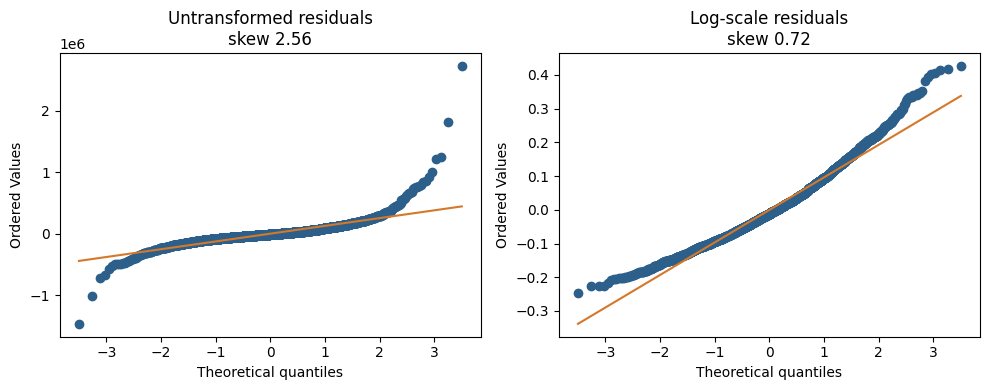

In [4]:
raw_columns = [
    "list_price", "square_feet", "lot_front", "lot_depth",
    "bedrooms", "washrooms", "parking_total", "garage", "latitude", "longitude",
]

def raw_design(frame):
    X = frame[raw_columns].copy()
    X["lot_front"] = X["lot_front"].fillna(0.0)
    X["lot_depth"] = X["lot_depth"].fillna(0.0)
    return sm.add_constant(X, has_constant="add")

raw_model = sm.OLS(train["sold_price"], raw_design(train)).fit()
raw_hat = raw_model.predict(raw_design(valid))
add_score("OLS, untransformed", raw_hat, valid["sold_price"])

log_target = pd.Series(np.log(train["sold_price"]), index=train.index, name="log_sold_price")
log_model = sm.OLS(log_target, train_X).fit()
log_hat = np.exp(log_model.predict(valid_X))
add_score("OLS, log scale", log_hat, valid["sold_price"])

print(f"Residual skew, untransformed: {raw_model.resid.skew():.2f}")
print(f"Residual skew, log scale: {pd.Series(log_model.resid).skew():.2f}")
print("Untransformed regression. Coefficients are in dollars of sold price.")
display(raw_model.summary())
print("Log-scale regression. The target is log sold price. A coefficient on a logged feature is an elasticity.")
display(log_model.summary())

rng = np.random.default_rng(0)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
panels = [
    (raw_model.resid, f"Untransformed residuals\nskew {raw_model.resid.skew():.2f}"),
    (log_model.resid, f"Log-scale residuals\nskew {pd.Series(log_model.resid).skew():.2f}"),
]
for ax, (resid, title) in zip(axes, panels):
    sample = rng.choice(np.asarray(resid), size=3000, replace=False)
    stats.probplot(sample, dist="norm", plot=ax)
    ax.set_title(title)
    ax.get_lines()[0].set_color("#2c5f8a")
    ax.get_lines()[1].set_color("#d4782a")
fig.tight_layout()
plt.show()

## V2: Time series on the log residual

The log regression has no time term. Its average residual over the whole training window is about zero, but the monthly mean can drift. The series here is that monthly mean. It reuses `log_model` and `numeric_design`; it does not refit the house-level coefficients.

An Augmented Dickey-Fuller test with a trend is run on the training months. A p-value under 0.05 means a unit root is rejected and the series is not differenced. Otherwise it is differenced once. The forecast model is a one-month autoregression plus a 12-month autoregression. When the series is not differenced, the model also has a constant level. A linear trend on top of that seasonal model does not converge here, so the scored model uses the constant.

The coefficient table is the time-series model: standard errors, z statistics, and p-values. The forecast is one number per validation month, in log price. Added to the log regression, it moves every home sold that month by the same percent.

Training months: 59, 2021-01 to 2025-11
ADF p-value with a trend: 0.0002
Differencing order 0, level term 'c'


Time-series coefficients


<class 'statsmodels.iolib.summary.Summary'>
"""
                                     SARIMAX Results                                      
==========================================================================================
Dep. Variable:                                  y   No. Observations:                   59
Model:             SARIMAX(1, 0, 0)x(1, 0, 0, 12)   Log Likelihood                 144.495
Date:                            Thu, 29 Oct 2026   AIC                           -280.991
Time:                                    17:06:28   BIC                           -273.676
Sample:                                01-01-2021   HQIC                          -278.251
                                     - 11-01-2025                                         
Covariance Type:                              opg                                         
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
intercept     -0.0046      0.002     -2.536      0.011      -0.008      -0.001
ar.L1          0.8717      0.043     20.394      0.000       0.788       0.956
ar.S.L12       0.3697      0.114      3.251      0.001       0.147       0.593
sigma2         0.0001    2.2e-05      4.964      0.000    6.62e-05       0.000
===================================================================================
Ljung-Box (L1) (Q):                  13.83   Jarque-Bera (JB):                 6.84
Prob(Q):                              0.00   Prob(JB):                         0.03
Heteroskedasticity (H):               0.17   Skew:                             0.84
Prob(H) (two-sided):                  0.00   Kurtosis:                         3.87
===================================================================================

Warnings:
[1] Covariance matrix calculated using the outer product of gradients (complex-step).
"""

In-sample R² on the monthly residual series: 0.885 (59 months). This is not a share of home-price variance.
Forecast log residual by validation month


,log_residual
2025-12-01,-0.0622
2026-01-01,-0.0603
2026-02-01,-0.0539
2026-03-01,-0.0537
2026-04-01,-0.0509
2026-05-01,-0.0541


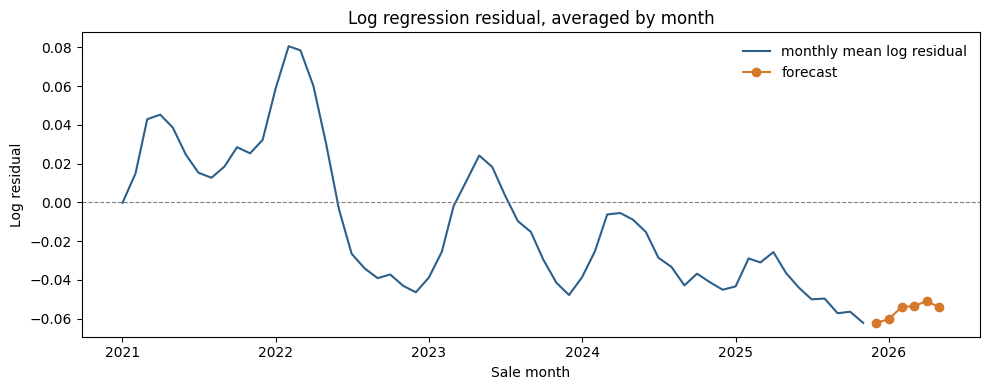

Log OLS + residual forecast: MdAPE 4.78%, MAPE 5.97%, median signed error +0.25%


{'model': 'Log OLS + residual forecast',
 'MdAPE': 4.78,
 'MAPE': 5.97,
 'median_signed_error': 0.25}

In [5]:
log_resid = pd.Series(log_model.resid, index=train.index)
monthly = log_resid.groupby(train["date_sold"].dt.to_period("M")).mean()
monthly.index = monthly.index.to_timestamp()
monthly = monthly.asfreq("MS")

adf_p = adfuller(monthly.dropna(), regression="ct", autolag="AIC")[1]
difference = 0 if adf_p < 0.05 else 1
trend = "c" if difference == 0 else "n"
print(f"Training months: {len(monthly)}, {monthly.index.min():%Y-%m} to {monthly.index.max():%Y-%m}")
print(f"ADF p-value with a trend: {adf_p:.4f}")
print(f"Differencing order {difference}, level term '{trend}'")

residual_model = SARIMAX(
    monthly.astype(float),
    order=(1, difference, 0),
    seasonal_order=(1, 0, 0, 12),
    trend=trend,
    enforce_stationarity=False,
    enforce_invertibility=False,
).fit(disp=False, maxiter=200)
forecast = residual_model.get_forecast(steps=6).predicted_mean
print("Time-series coefficients")
display(residual_model.summary())
fitted = residual_model.fittedvalues.dropna()
actual = monthly.astype(float).reindex(fitted.index).dropna()
fitted = fitted.reindex(actual.index)
ss_res = float(np.sum((actual - fitted) ** 2))
ss_tot = float(np.sum((actual - actual.mean()) ** 2))
print(
    f"In-sample R² on the monthly residual series: {1 - ss_res / ss_tot:.3f} "
    f"({len(actual)} months). This is not a share of home-price variance."
)
print("Forecast log residual by validation month")
display(forecast.rename("log_residual").to_frame().round(4))

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(monthly.index, monthly, color="#2c5f8a", label="monthly mean log residual")
ax.plot(forecast.index, forecast, color="#d4782a", marker="o", label="forecast")
ax.axhline(0, color="0.5", lw=0.8, ls="--")
ax.set_ylabel("Log residual")
ax.set_xlabel("Sale month")
ax.set_title("Log regression residual, averaged by month")
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

valid_month = valid["date_sold"].dt.to_period("M").dt.to_timestamp()
adjustment = valid_month.map(forecast)
adjusted = np.exp(log_model.predict(valid_X) + adjustment.to_numpy())
add_score("Log OLS + residual forecast", adjusted, valid["sold_price"])

## V3: Pulse for the 2022 peak, then a lower level

From EDA, we noted the period of 2021-2022 (COVID) might have had abnormal remainder behaviors, affecting the current short-term predictions, assuming there's no such catastrophic event in the next couple months. Thus we want to isolate the effect of COVID errors from the normal ones.

Same log regression, and the same monthly residual series. The only change is two extra terms in the time-series model, dated from that training series:

- **Pulse.** January through May 2022. Those five months are the spike, about +0.06 to +0.08 in the log residual. June 2022 is back near zero. The pulse is 0 in the forecast.
- **Level shift.** On from June 2022 through the end of the sample, and still on for December 2025–May 2026. The post-spike gap did not return to the 2021 level.

The autoregression is unchanged: one month, twelve months, and a constant. The coefficient table shows whether the two terms still matter once that autoregression is in the model.

Time-series coefficients with a 2022 pulse and a level shift


<class 'statsmodels.iolib.summary.Summary'>
"""
                                     SARIMAX Results                                      
==========================================================================================
Dep. Variable:                                  y   No. Observations:                   59
Model:             SARIMAX(1, 0, 0)x(1, 0, 0, 12)   Log Likelihood                 147.450
Date:                            Thu, 29 Oct 2026   AIC                           -282.901
Time:                                    17:06:30   BIC                           -271.929
Sample:                                01-01-2021   HQIC                          -278.790
                                     - 11-01-2025                                         
Covariance Type:                              opg                                         
===============================================================================
                  coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------
intercept      -0.0017      0.006     -0.262      0.793      -0.014       0.011
pulse_2022     -0.0060      0.043     -0.138      0.890      -0.091       0.079
level_shift    -0.0306      0.066     -0.464      0.643      -0.160       0.099
ar.L1           0.8705      0.086     10.127      0.000       0.702       1.039
ar.S.L12        0.3712      0.126      2.947      0.003       0.124       0.618
sigma2       9.613e-05    2.2e-05      4.379      0.000    5.31e-05       0.000
===================================================================================
Ljung-Box (L1) (Q):                   7.51   Jarque-Bera (JB):                13.19
Prob(Q):                              0.01   Prob(JB):                         0.00
Heteroskedasticity (H):               0.20   Skew:                             1.14
Prob(H) (two-sided):                  0.00   Kurtosis:                         4.30
===================================================================================

Warnings:
[1] Covariance matrix calculated using the outer product of gradients (complex-step).
"""

In-sample R² on the monthly residual series: 0.897 (59 months).
Forecast log residual by validation month


,log_residual
2025-12-01,-0.0617
2026-01-01,-0.0594
2026-02-01,-0.0526
2026-03-01,-0.0521
2026-04-01,-0.0490
2026-05-01,-0.0520


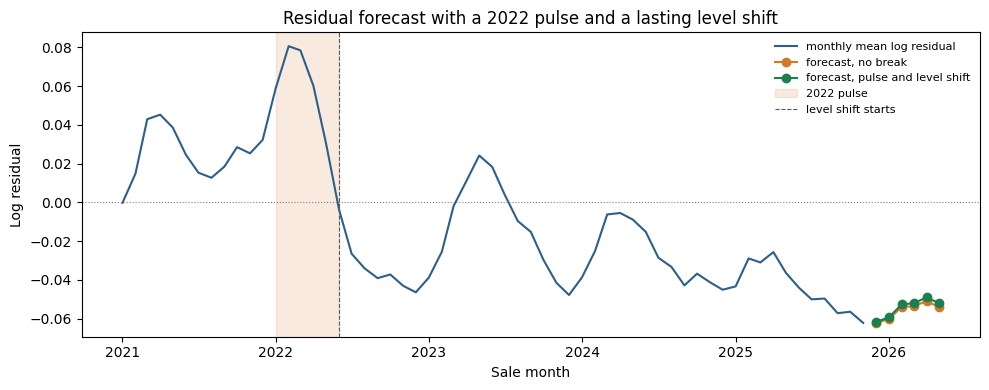

Log OLS + 2022 pulse and level shift: MdAPE 4.80%, MAPE 5.98%, median signed error +0.41%


{'model': 'Log OLS + 2022 pulse and level shift',
 'MdAPE': 4.8,
 'MAPE': 5.98,
 'median_signed_error': 0.41}

In [6]:
pulse_start = pd.Timestamp("2022-01-01")
pulse_end = pd.Timestamp("2022-05-01")
shift_start = pd.Timestamp("2022-06-01")


def intervention(index):
    frame = pd.DataFrame(index=index)
    frame["pulse_2022"] = ((index >= pulse_start) & (index <= pulse_end)).astype(float)
    frame["level_shift"] = (index >= shift_start).astype(float)
    return frame


break_model = SARIMAX(
    monthly.astype(float),
    exog=intervention(monthly.index),
    order=(1, difference, 0),
    seasonal_order=(1, 0, 0, 12),
    trend=trend,
    enforce_stationarity=False,
    enforce_invertibility=False,
).fit(disp=False, maxiter=200)
print("Time-series coefficients with a 2022 pulse and a level shift")
display(break_model.summary())

fitted_break = break_model.fittedvalues.dropna()
actual_break = monthly.astype(float).reindex(fitted_break.index).dropna()
fitted_break = fitted_break.reindex(actual_break.index)
ss_res = float(np.sum((actual_break - fitted_break) ** 2))
ss_tot = float(np.sum((actual_break - actual_break.mean()) ** 2))
print(
    f"In-sample R² on the monthly residual series: {1 - ss_res / ss_tot:.3f} "
    f"({len(actual_break)} months)."
)

future_index = pd.date_range(monthly.index.max() + pd.DateOffset(months=1), periods=6, freq="MS")
forecast_break = break_model.get_forecast(steps=6, exog=intervention(future_index)).predicted_mean
print("Forecast log residual by validation month")
display(forecast_break.rename("log_residual").to_frame().round(4))

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(monthly.index, monthly, color="#2c5f8a", label="monthly mean log residual")
ax.plot(forecast.index, forecast, color="#d4782a", marker="o", label="forecast, no break")
ax.plot(forecast_break.index, forecast_break, color="#1b7f4e", marker="o", label="forecast, pulse and level shift")
ax.axvspan(pulse_start, shift_start, color="#d4782a", alpha=0.15, label="2022 pulse")
ax.axvline(shift_start, color="0.35", lw=0.8, ls="--", label="level shift starts")
ax.axhline(0, color="0.5", lw=0.8, ls=":")
ax.set_ylabel("Log residual")
ax.set_xlabel("Sale month")
ax.set_title("Residual forecast with a 2022 pulse and a lasting level shift")
ax.legend(frameon=False, fontsize=8)
fig.tight_layout()
plt.show()

adjustment_break = valid_month.map(forecast_break)
adjusted_break = np.exp(log_model.predict(valid_X) + adjustment_break.to_numpy())
add_score("Log OLS + 2022 pulse and level shift", adjusted_break, valid["sold_price"])

## Boosted trees

Gradient boosting is an ensemble of small trees. Both fits predict log sold price and are exponentiated back to dollars, on the same December 2025–May 2026 window.

The numeric model reuses `numeric_design`. Two time columns are added from information that would be known when the home is listed. `market_lag` is the median log sold-to-list ratio in the month before `date_listed`, computed from training sales only. Listings after November 2025 get the November 2025 value, so validation outcomes are not used. Month of listing is stored as sine and cosine.

The second model adds 20 components from a TF-IDF of `remarks`, reduced with a truncated SVD. The word matrix and the SVD are fit on the training remarks only. Remarks are on the list-aware test file, so this can be ported later.

A boosted tree has no coefficient table. For the numeric model, the table is a permutation check on 3,000 validation homes: how many percentage points of MdAPE are lost when that column is shuffled.

In [7]:
from sklearn.decomposition import TruncatedSVD
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.inspection import permutation_importance

log_ratio = np.log(train["sold_price"] / train["list_price"])
ratio_by_month = log_ratio.groupby(train["date_sold"].dt.to_period("M")).median()
lag_by_list_month = ratio_by_month.shift(1)
last_train_month = ratio_by_month.index.max()
latest_ratio = float(ratio_by_month.iloc[-1])


def market_lag(frame):
    keys = frame["date_listed"].dt.to_period("M")
    lag = keys.map(lag_by_list_month).astype(float)
    lag = lag.mask(keys > last_train_month, latest_ratio)
    return lag.fillna(0.0).to_numpy()


def tree_frame(frame):
    X = numeric_design(frame)
    listed_month = frame["date_listed"].dt.month.to_numpy()
    X["listed_month_sin"] = np.sin(2 * np.pi * listed_month / 12)
    X["listed_month_cos"] = np.cos(2 * np.pi * listed_month / 12)
    X["market_lag"] = market_lag(frame)
    return X


tree_train = tree_frame(train)
tree_valid = tree_frame(valid)
log_sold = np.log(train["sold_price"].to_numpy())
booster = HistGradientBoostingRegressor(
    max_iter=200,
    learning_rate=0.08,
    max_depth=6,
    min_samples_leaf=40,
    l2_regularization=0.1,
    random_state=0,
)
booster.fit(tree_train, log_sold)
numeric_hat = np.exp(booster.predict(tree_valid))
add_score("Boosted trees, numeric", numeric_hat, valid["sold_price"])

def mdape_score(estimator, X, y_log):
    predicted = np.exp(estimator.predict(X))
    sold = np.exp(np.asarray(y_log))
    return -float(np.median(np.abs(predicted - sold) / sold))

rng = np.random.default_rng(0)
sample = rng.choice(len(tree_valid), size=3000, replace=False)
importance = permutation_importance(
    booster,
    tree_valid.iloc[sample],
    np.log(valid["sold_price"].to_numpy()[sample]),
    n_repeats=4,
    random_state=0,
    scoring=mdape_score,
)
importance_table = pd.DataFrame(
    {
        "feature": tree_train.columns,
        "MdAPE increase, pp": np.round(100 * importance.importances_mean, 3),
    }
).sort_values("MdAPE increase, pp", ascending=False)
display(importance_table)

vectorizer = TfidfVectorizer(
    lowercase=True,
    stop_words="english",
    ngram_range=(1, 2),
    min_df=80,
    max_df=0.5,
    max_features=3000,
    sublinear_tf=True,
    token_pattern=r"(?u)\b[a-zA-Z]{2,}(?:[-'][a-zA-Z]+)*\b",
    dtype=np.float32,
)
svd = TruncatedSVD(n_components=20, random_state=0)
text_train = svd.fit_transform(vectorizer.fit_transform(train["remarks"]))
text_valid = svd.transform(vectorizer.transform(valid["remarks"]))
print(f"Remarks SVD: 20 components explain {svd.explained_variance_ratio_.sum():.1%} of the training TF-IDF")

text_booster = HistGradientBoostingRegressor(
    max_iter=200,
    learning_rate=0.08,
    max_depth=6,
    min_samples_leaf=40,
    l2_regularization=0.1,
    random_state=0,
)
text_booster.fit(np.hstack([tree_train.to_numpy(), text_train]), log_sold)
text_hat = np.exp(text_booster.predict(np.hstack([tree_valid.to_numpy(), text_valid])))
add_score("Boosted trees, numeric + remarks", text_hat, valid["sold_price"])

Boosted trees, numeric: MdAPE 4.83%, MAPE 5.97%, median signed error +1.43%


,feature,"MdAPE increase, pp"
0,log_list_price,35.929
3,log_lot_front,0.608
1,log_square_feet,0.471
6,washrooms,0.364
2,lot_missing,0.298
5,bedrooms,0.153
4,lot_depth,0.140
10,longitude,0.120
9,latitude,0.061
8,garage,0.041


Remarks SVD: 20 components explain 11.1% of the training TF-IDF


Boosted trees, numeric + remarks: MdAPE 4.85%, MAPE 5.98%, median signed error +1.66%


{'model': 'Boosted trees, numeric + remarks',
 'MdAPE': 4.85,
 'MAPE': 5.98,
 'median_signed_error': 1.66}

## V5: XGBoost

Same columns as the numeric V4 model. The grids cover depth, learning rate, and number of trees for the boosters, and depth plus minimum leaf size for the forest. XGBoost's first pass preferred the deepest trees, the lowest learning rate, and the most trees, so the search also checks depth 10, 600 trees, and a learning rate of 0.03. CatBoost preferred the higher learning rate, so the search also checks 0.15.

The search fits on sales through June 2025 and scores July–November 2025. The winner is refit on every training sale, then scored once on December 2025–May 2026. A shuffled cross-validation would train on later sales and score earlier ones, so the search uses this time cut.

XGBoost uses histogram trees, a row sample of 0.8, a column sample of 0.8, and a minimum child weight of 20. CatBoost uses 300 iterations. The forest uses 200 trees and half the columns at each split.

In [8]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import ParameterGrid
from xgboost import XGBRegressor
from catboost import CatBoostRegressor

tune_start = pd.Timestamp("2025-07-01")
fit_mask = (train["date_sold"] < tune_start).to_numpy()
X_fit = tree_train.iloc[fit_mask]
y_fit = np.log(train["sold_price"].to_numpy()[fit_mask])
X_tune = tree_train.iloc[~fit_mask]
sold_tune = train["sold_price"].to_numpy()[~fit_mask]
print(
    f"Parameter search: fit {fit_mask.sum():,} sales through June 2025, "
    f"score {(~fit_mask).sum():,} sales from July through November 2025"
)


def inner_mdape(model):
    model.fit(X_fit, y_fit)
    predicted = np.exp(model.predict(X_tune))
    error = np.abs(predicted - sold_tune) / sold_tune
    return round(float(np.median(error) * 100), 3)


def validation_score(name, model):
    model.fit(tree_train, log_sold)
    predicted = np.exp(model.predict(tree_valid))
    return add_score(name, predicted, valid["sold_price"])


xgb_candidates = list(ParameterGrid(
    {"max_depth": [4, 6, 8], "learning_rate": [0.05, 0.1], "n_estimators": [200, 400]}
))
xgb_candidates.extend([
    {"max_depth": 8, "learning_rate": 0.05, "n_estimators": 600},
    {"max_depth": 8, "learning_rate": 0.03, "n_estimators": 600},
    {"max_depth": 10, "learning_rate": 0.05, "n_estimators": 400},
    {"max_depth": 10, "learning_rate": 0.05, "n_estimators": 600},
])
xgb_rows = []
for params in xgb_candidates:
    score = inner_mdape(
        XGBRegressor(
            **params,
            min_child_weight=20,
            subsample=0.8,
            colsample_bytree=0.8,
            reg_lambda=1.0,
            tree_method="hist",
            n_jobs=-1,
            random_state=0,
            verbosity=0,
        )
    )
    xgb_rows.append({**params, "inner_MdAPE": score})
xgb_table = pd.DataFrame(xgb_rows).sort_values(
    ["inner_MdAPE", "n_estimators", "max_depth", "learning_rate"]
).reset_index(drop=True)
display(xgb_table)
best_xgb = xgb_table.iloc[0]
validation_score(
    f"V5 XGBoost, depth {int(best_xgb.max_depth)}, lr {best_xgb.learning_rate:g}, {int(best_xgb.n_estimators)} trees",
    XGBRegressor(
        n_estimators=int(best_xgb.n_estimators),
        max_depth=int(best_xgb.max_depth),
        learning_rate=float(best_xgb.learning_rate),
        min_child_weight=20,
        subsample=0.8,
        colsample_bytree=0.8,
        reg_lambda=1.0,
        tree_method="hist",
        n_jobs=-1,
        random_state=0,
        verbosity=0,
    ),
)

Parameter search: fit 130,045 sales through June 2025, score 9,886 sales from July through November 2025


,learning_rate,max_depth,n_estimators,inner_MdAPE
0,0.05,8,400,4.682
1,0.05,8,600,4.698
2,0.03,8,600,4.703
3,0.10,6,400,4.723
4,0.10,8,400,4.742
5,0.05,8,200,4.750
6,0.10,6,200,4.763
7,0.10,4,400,4.766
8,0.10,8,200,4.767
9,0.05,10,400,4.775


V5 XGBoost, depth 8, lr 0.05, 400 trees: MdAPE 4.69%, MAPE 5.92%, median signed error +1.28%


{'model': 'V5 XGBoost, depth 8, lr 0.05, 400 trees',
 'MdAPE': 4.69,
 'MAPE': 5.92,
 'median_signed_error': 1.28}

## V6: Catboost

In [9]:
cat_candidates = list(ParameterGrid(
    {"depth": [6, 8], "learning_rate": [0.05, 0.1], "l2_leaf_reg": [3, 10]}
))
cat_candidates.extend([
    {"depth": 6, "learning_rate": 0.15, "l2_leaf_reg": 3},
    {"depth": 6, "learning_rate": 0.15, "l2_leaf_reg": 1},
])
cat_rows = []
for params in cat_candidates:
    score = inner_mdape(
        CatBoostRegressor(
            **params,
            iterations=300,
            loss_function="RMSE",
            random_seed=0,
            verbose=0,
            allow_writing_files=False,
            thread_count=-1,
        )
    )
    cat_rows.append({**params, "inner_MdAPE": score})
cat_table = pd.DataFrame(cat_rows).sort_values(
    ["inner_MdAPE", "depth", "l2_leaf_reg", "learning_rate"]
).reset_index(drop=True)
display(cat_table)
best_cat = cat_table.iloc[0]
validation_score(
    f"V6 CatBoost, depth {int(best_cat.depth)}, lr {best_cat.learning_rate:g}, l2 {best_cat.l2_leaf_reg:g}",
    CatBoostRegressor(
        depth=int(best_cat.depth),
        learning_rate=float(best_cat.learning_rate),
        l2_leaf_reg=float(best_cat.l2_leaf_reg),
        iterations=300,
        loss_function="RMSE",
        random_seed=0,
        verbose=0,
        allow_writing_files=False,
        thread_count=-1,
    ),
)

,depth,l2_leaf_reg,learning_rate,inner_MdAPE
0,6,3,0.10,4.763
1,8,10,0.10,4.780
2,8,3,0.10,4.784
3,6,1,0.15,4.792
4,6,3,0.15,4.792
5,6,10,0.10,4.814
6,8,10,0.05,4.846
7,8,3,0.05,4.847
8,6,3,0.05,4.872
9,6,10,0.05,4.912


V6 CatBoost, depth 6, lr 0.1, l2 3: MdAPE 4.81%, MAPE 5.97%, median signed error +1.32%


{'model': 'V6 CatBoost, depth 6, lr 0.1, l2 3',
 'MdAPE': 4.81,
 'MAPE': 5.97,
 'median_signed_error': 1.32}

## V7: Random forest

In [10]:
rf_rows = []
for params in ParameterGrid(
    {"max_depth": [12, 20, 32], "min_samples_leaf": [5, 20]}
):
    score = inner_mdape(
        RandomForestRegressor(
            **params,
            n_estimators=200,
            max_features=0.5,
            n_jobs=-1,
            random_state=0,
        )
    )
    rf_rows.append({**params, "inner_MdAPE": score})
rf_table = pd.DataFrame(rf_rows).sort_values(
    ["inner_MdAPE", "max_depth", "min_samples_leaf"],
    ascending=[True, True, False],
).reset_index(drop=True)
display(rf_table)
best_rf = rf_table.iloc[0]
validation_score(
    f"V7 Random forest, depth {int(best_rf.max_depth)}, leaf {int(best_rf.min_samples_leaf)}",
    RandomForestRegressor(
        n_estimators=200,
        max_depth=int(best_rf.max_depth),
        min_samples_leaf=int(best_rf.min_samples_leaf),
        max_features=0.5,
        n_jobs=-1,
        random_state=0,
    ),
)

,max_depth,min_samples_leaf,inner_MdAPE
0,20,5,5.015
1,32,5,5.023
2,20,20,5.058
3,32,20,5.067
4,12,5,5.118
5,12,20,5.153


V7 Random forest, depth 20, leaf 5: MdAPE 5.05%, MAPE 6.24%, median signed error +2.36%


{'model': 'V7 Random forest, depth 20, leaf 5',
 'MdAPE': 5.05,
 'MAPE': 6.24,
 'median_signed_error': 2.36}

## V8: XGBoost with the home's own attributes

Same settings as V5: depth 8, learning rate 0.05, 400 trees. Adds property type, house style, municipality, lot area, and a flag that the listed size was a range.

In [11]:
from xgboost import XGBRegressor

xgb_settings = dict(
    n_estimators=400,
    max_depth=8,
    learning_rate=0.05,
    min_child_weight=20,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_lambda=1.0,
    tree_method="hist",
    enable_categorical=True,
    n_jobs=-1,
    random_state=0,
    verbosity=0,
)
category_levels = {
    column: pd.Index(train[column].dropna().unique())
    for column in ["house_type_name", "house_style", "municipality"]
}


def home_attributes(frame):
    X = tree_frame(frame)
    X["lot_area"] = frame["lot_front"] * frame["lot_depth"]
    X["area_is_range"] = frame["house_area"].astype(str).str.contains("-", regex=False).astype(float)
    for column, levels in category_levels.items():
        X[column] = pd.Categorical(frame[column], categories=levels)
    return X


x8_train = home_attributes(train)
x8_valid = home_attributes(valid)
v8_model = XGBRegressor(**xgb_settings)
v8_model.fit(x8_train, log_sold)
add_score("V8 XGBoost, type, style, and lot", np.exp(v8_model.predict(x8_valid)), valid["sold_price"])

V8 XGBoost, type, style, and lot: MdAPE 4.63%, MAPE 5.87%, median signed error +1.30%


{'model': 'V8 XGBoost, type, style, and lot',
 'MdAPE': 4.63,
 'MAPE': 5.87,
 'median_signed_error': 1.3}

## V9: Peer ask

Peer ask is how expensive this home’s list price is, per square foot, compared with similar homes that already sold.

It is the list price per square foot divided by the median sold price per square foot of earlier sales of the same property type in the same community.

V8, plus list price per square foot divided by the median sold price per square foot of earlier sales of the same type in the same community. The median uses training sales that closed before the listing month, so a home's own sale is not included. A community with fewer than 30 of those sales uses the type-level median.

In [12]:
def month_ord(dates):
    return (dates.dt.year * 12 + dates.dt.month).to_numpy()


def past_median_table(reference, values, group_columns):
    history = reference.loc[:, group_columns].copy()
    history["month_ord"] = month_ord(reference["date_sold"])
    history["value"] = np.asarray(values, dtype=float)
    history = history.dropna()
    query_ords = np.arange(int(history["month_ord"].min()), int(history["month_ord"].max()) + 8)
    pieces = []
    for key, group in history.groupby(group_columns, observed=True, sort=False):
        group = group.sort_values("month_ord")
        sale_ords = group["month_ord"].to_numpy()
        vals = group["value"].to_numpy()
        ends = np.searchsorted(sale_ords, query_ords, side="left")
        medians = np.full(len(query_ords), np.nan)
        last_end = -1
        last_med = np.nan
        for i, end in enumerate(ends):
            end = int(end)
            if end == 0:
                continue
            if end != last_end:
                last_med = float(np.median(vals[:end]))
                last_end = end
            medians[i] = last_med
        key = key if isinstance(key, tuple) else (key,)
        piece = {"month_ord": query_ords, "median": medians, "count": ends}
        for column, value in zip(group_columns, key):
            piece[column] = value
        pieces.append(pd.DataFrame(piece))
    return pd.concat(pieces, ignore_index=True)


def lookup_past(query, table, group_columns):
    keys = query.loc[:, list(group_columns)].copy()
    keys["month_ord"] = month_ord(query["date_listed"])
    merged = keys.merge(table, on=list(group_columns) + ["month_ord"], how="left")
    if len(merged) != len(query):
        raise ValueError("past-median lookup changed the number of rows")
    median = merged["median"].to_numpy(dtype=float)
    count = merged["count"].fillna(0).to_numpy(dtype=float)
    return median, count


sold_pps = (train["sold_price"] / train["square_feet"]).to_numpy()
peer_table = past_median_table(train, sold_pps, ["community", "house_type_name"])
type_pps_table = past_median_table(train, sold_pps, ["house_type_name"])
min_peer_sales = 30


def peer_ask(frame):
    list_pps = (frame["list_price"] / frame["square_feet"]).to_numpy(dtype=float)
    type_median, _ = lookup_past(frame, type_pps_table, ["house_type_name"])
    community_median, community_count = lookup_past(frame, peer_table, ["community", "house_type_name"])
    chosen = np.where(community_count >= min_peer_sales, community_median, type_median)
    ratio = np.full(len(frame), np.nan)
    ok = np.isfinite(chosen) & (chosen > 0)
    ratio[ok] = list_pps[ok] / chosen[ok]
    return ratio


def with_peer(frame, base):
    X = base.copy()
    X["peer_ask"] = peer_ask(frame)
    return X


_, train_peer_count = lookup_past(train, peer_table, ["community", "house_type_name"])
print(f"Community median used for {(train_peer_count >= min_peer_sales).mean():.0%} of training rows")
x9_train = with_peer(train, x8_train)
x9_valid = with_peer(valid, x8_valid)
v9_model = XGBRegressor(**xgb_settings)
v9_model.fit(x9_train, log_sold)
add_score("V9 XGBoost, plus peer ask", np.exp(v9_model.predict(x9_valid)), valid["sold_price"])

Community median used for 84% of training rows


V9 XGBoost, plus peer ask: MdAPE 4.53%, MAPE 5.73%, median signed error +1.27%


{'model': 'V9 XGBoost, plus peer ask',
 'MdAPE': 4.53,
 'MAPE': 5.73,
 'median_signed_error': 1.27}

## V10: Recent discount by property type

V9, plus the median sold-to-list ratio for that property type among training sales that closed before the listing month.

In [13]:
sold_to_list = (train["sold_price"] / train["list_price"]).to_numpy()
type_discount_table = past_median_table(train, sold_to_list, ["house_type_name"])


def with_type_discount(frame, base):
    X = base.copy()
    discount, _ = lookup_past(frame, type_discount_table, ["house_type_name"])
    X["type_discount"] = discount
    return X


x10_train = with_type_discount(train, x9_train)
x10_valid = with_type_discount(valid, x9_valid)
print(f"Type discount on training rows: median {np.nanmedian(x10_train['type_discount']):.3f}")
v10_model = XGBRegressor(**xgb_settings)
v10_model.fit(x10_train, log_sold)
add_score("V10 XGBoost, plus type discount", np.exp(v10_model.predict(x10_valid)), valid["sold_price"])

Type discount on training rows: median 1.002


V10 XGBoost, plus type discount: MdAPE 4.63%, MAPE 5.78%, median signed error +1.53%


{'model': 'V10 XGBoost, plus type discount',
 'MdAPE': 4.63,
 'MAPE': 5.78,
 'median_signed_error': 1.53}

## V11: Retune the best feature set

V8, V9, V10, and V10 with the V2 residual forecast attached to the listing month are compared on sales from July through November 2025. The winner is retuned over depth, learning rate, and number of trees on that slice, refit on every training sale, and scored once on December 2025–May 2026.

In [14]:
def list_month_factor(frame):
    listed = frame["date_listed"].dt.to_period("M").dt.to_timestamp()
    previous = listed - pd.DateOffset(months=1)
    values = listed.map(forecast)
    lagged = previous.map(monthly)
    return values.fillna(lagged).fillna(0.0).to_numpy()


def with_list_month_factor(frame, base):
    X = base.copy()
    X["list_month_factor"] = list_month_factor(frame)
    return X


x11_train = with_list_month_factor(train, x10_train)
x11_valid = with_list_month_factor(valid, x10_valid)
fit_rows = (train["date_sold"] < pd.Timestamp("2025-07-01")).to_numpy()
sold_tune = train["sold_price"].to_numpy()[~fit_rows]
log_fit = np.log(train["sold_price"].to_numpy()[fit_rows])
feature_sets = {
    "V8 attributes": (x8_train, x8_valid),
    "V9 peer ask": (x9_train, x9_valid),
    "V10 type discount": (x10_train, x10_valid),
    "V10 plus listing-month factor": (x11_train, x11_valid),
}
feature_rows = []
for name, (X_all, _) in feature_sets.items():
    model = XGBRegressor(**xgb_settings)
    model.fit(X_all.iloc[fit_rows], log_fit)
    predicted = np.exp(model.predict(X_all.iloc[~fit_rows]))
    feature_rows.append({
        "features": name,
        "inner_MdAPE": round(float(np.median(np.abs(predicted - sold_tune) / sold_tune) * 100), 3),
    })
feature_table = pd.DataFrame(feature_rows).sort_values("inner_MdAPE", kind="mergesort").reset_index(drop=True)
display(feature_table)
chosen_features = feature_table.iloc[0]["features"]
X_search, X_search_valid = feature_sets[chosen_features]

grid_rows = []
for params in ParameterGrid({"max_depth": [6, 8, 10], "learning_rate": [0.05, 0.1], "n_estimators": [300, 500]}):
    model = XGBRegressor(**{**xgb_settings, **params})
    model.fit(X_search.iloc[fit_rows], log_fit)
    predicted = np.exp(model.predict(X_search.iloc[~fit_rows]))
    grid_rows.append({
        **params,
        "inner_MdAPE": round(float(np.median(np.abs(predicted - sold_tune) / sold_tune) * 100), 3),
    })
grid_table = pd.DataFrame(grid_rows).sort_values(
    ["inner_MdAPE", "n_estimators", "max_depth", "learning_rate"], kind="mergesort"
).reset_index(drop=True)
display(grid_table)
best = grid_table.iloc[0]
v11_model = XGBRegressor(**{
    **xgb_settings,
    "n_estimators": int(best.n_estimators),
    "max_depth": int(best.max_depth),
    "learning_rate": float(best.learning_rate),
})
v11_model.fit(X_search, log_sold)
add_score(
    f"V11 XGBoost, {chosen_features}, depth {int(best.max_depth)}, lr {best.learning_rate:g}, {int(best.n_estimators)} trees",
    np.exp(v11_model.predict(X_search_valid)),
    valid["sold_price"],
)

,features,inner_MdAPE
0,V10 plus listing-month factor,4.542
1,V10 type discount,4.567
2,V8 attributes,4.685
3,V9 peer ask,4.707


,learning_rate,max_depth,n_estimators,inner_MdAPE
0,0.05,10,500,4.513
1,0.10,6,500,4.530
2,0.05,8,500,4.547
3,0.05,8,300,4.554
4,0.10,6,300,4.565
5,0.05,6,500,4.568
6,0.05,10,300,4.569
7,0.10,8,500,4.587
8,0.05,6,300,4.597
9,0.10,8,300,4.598


V11 XGBoost, V10 plus listing-month factor, depth 10, lr 0.05, 500 trees: MdAPE 4.57%, MAPE 5.75%, median signed error +1.23%


{'model': 'V11 XGBoost, V10 plus listing-month factor, depth 10, lr 0.05, 500 trees',
 'MdAPE': 4.57,
 'MAPE': 5.75,
 'median_signed_error': 1.23}

## V12: LightGBM

Same columns as V9. The search fits on sales through June 2025 and scores July–November 2025, then the winner is refit on every training sale and scored once on December 2025–May 2026. The number of leaves takes the place of a fixed depth. Each tree uses a row sample of 0.8, a column sample of 0.8, and at least 20 rows in a leaf.

In [15]:
from lightgbm import LGBMRegressor
from sklearn.model_selection import ParameterGrid

lgb_categories = ["house_type_name", "house_style", "municipality"]
lgb_fixed = dict(
    min_child_samples=20,
    subsample=0.8,
    subsample_freq=1,
    colsample_bytree=0.8,
    reg_lambda=1.0,
    random_state=0,
    n_jobs=-1,
    verbosity=-1,
)
fit_rows = (train["date_sold"] < pd.Timestamp("2025-07-01")).to_numpy()
sold_inner = train["sold_price"].to_numpy()[~fit_rows]
log_fit = np.log(train["sold_price"].to_numpy()[fit_rows])
lgb_candidates = list(ParameterGrid(
    {"num_leaves": [31, 63, 127], "learning_rate": [0.05, 0.1], "n_estimators": [300, 500]}
))
lgb_candidates.extend([
    {"num_leaves": 255, "learning_rate": 0.05, "n_estimators": 500},
    {"num_leaves": 127, "learning_rate": 0.05, "n_estimators": 700},
    {"num_leaves": 127, "learning_rate": 0.03, "n_estimators": 700},
])


def inner_lightgbm(params):
    model = LGBMRegressor(**lgb_fixed, **params)
    model.fit(x9_train.iloc[fit_rows], log_fit, categorical_feature=lgb_categories)
    predicted = np.exp(model.predict(x9_train.iloc[~fit_rows]))
    error = np.abs(predicted - sold_inner) / sold_inner
    return round(float(np.median(error) * 100), 3)


lgb_rows = []
for params in lgb_candidates:
    lgb_rows.append({**params, "inner_MdAPE": inner_lightgbm(params)})
lgb_table = pd.DataFrame(lgb_rows).sort_values(
    ["inner_MdAPE", "n_estimators", "num_leaves", "learning_rate"], kind="mergesort"
).reset_index(drop=True)
display(lgb_table)
best_lgb = lgb_table.iloc[0]
v12_model = LGBMRegressor(
    **lgb_fixed,
    num_leaves=int(best_lgb.num_leaves),
    learning_rate=float(best_lgb.learning_rate),
    n_estimators=int(best_lgb.n_estimators),
)
v12_model.fit(x9_train, log_sold, categorical_feature=lgb_categories)
add_score(
    f"V12 LightGBM, {int(best_lgb.num_leaves)} leaves, lr {best_lgb.learning_rate:g}, {int(best_lgb.n_estimators)} trees",
    np.exp(v12_model.predict(x9_valid)),
    valid["sold_price"],
)

,learning_rate,n_estimators,num_leaves,inner_MdAPE
0,0.03,700,127,4.620
1,0.05,700,127,4.649
2,0.05,500,255,4.660
3,0.05,500,127,4.670
4,0.10,500,63,4.685
5,0.10,500,31,4.692
6,0.10,300,63,4.705
7,0.05,300,127,4.706
8,0.05,500,63,4.717
9,0.10,300,127,4.718


V12 LightGBM, 127 leaves, lr 0.03, 700 trees: MdAPE 4.54%, MAPE 5.73%, median signed error +1.40%


{'model': 'V12 LightGBM, 127 leaves, lr 0.03, 700 trees',
 'MdAPE': 4.54,
 'MAPE': 5.73,
 'median_signed_error': 1.4}

## V13: LightGBM with the listing-month factor

Same settings as V12, plus the V2 residual forecast on the listing month. A listing after November 2025 gets the forecast. An earlier listing gets the previous month's mean log residual.

In [16]:
x13_train = with_list_month_factor(train, x9_train)
x13_valid = with_list_month_factor(valid, x9_valid)
v13_model = LGBMRegressor(
    **lgb_fixed,
    num_leaves=int(best_lgb.num_leaves),
    learning_rate=float(best_lgb.learning_rate),
    n_estimators=int(best_lgb.n_estimators),
)
v13_model.fit(x13_train, log_sold, categorical_feature=lgb_categories)
add_score(
    "V13 LightGBM, plus listing-month factor",
    np.exp(v13_model.predict(x13_valid)),
    valid["sold_price"],
)

V13 LightGBM, plus listing-month factor: MdAPE 4.51%, MAPE 5.68%, median signed error +1.16%


{'model': 'V13 LightGBM, plus listing-month factor',
 'MdAPE': 4.51,
 'MAPE': 5.68,
 'median_signed_error': 1.16}

## V14: Monthly adjustment on V9

V9's price, multiplied by `exp(weight × listing-month factor)`. The weight is chosen on sales from July through November 2025, using a V9 model fit only through June 2025. That weight is then applied to the V9 model fit on every training sale. December 2025–May 2026 is scored once.

In [17]:
early = (train["date_sold"] < pd.Timestamp("2025-07-01")).to_numpy()
log_early = np.log(train["sold_price"].to_numpy()[early])
sold_late = train["sold_price"].to_numpy()[~early]
factor_late = list_month_factor(train)[~early]
factor_valid = list_month_factor(valid)


def adjustment_table(log_pred, sold, factor):
    rows = []
    for weight in np.round(np.arange(0.0, 1.51, 0.05), 2):
        predicted = np.exp(log_pred + weight * factor)
        signed = 100 * (predicted - sold) / sold
        rows.append({
            "weight": float(weight),
            "inner_MdAPE": round(float(np.median(np.abs(signed))), 3),
            "inner_signed": round(float(np.median(signed)), 3),
        })
    table = pd.DataFrame(rows)
    table["abs_signed"] = table["inner_signed"].abs()
    return table.sort_values(
        ["inner_MdAPE", "abs_signed", "weight"], kind="mergesort"
    ).drop(columns="abs_signed").reset_index(drop=True)


inner_v9 = XGBRegressor(**xgb_settings)
inner_v9.fit(x9_train.iloc[early], log_early)
v9_weights = adjustment_table(inner_v9.predict(x9_train.iloc[~early]), sold_late, factor_late)
display(v9_weights)
v9_weight = float(v9_weights.iloc[0]["weight"])
print(f"V9 adjustment weight {v9_weight:g}; validation factor median {np.median(factor_valid):.3f}")
add_score(
    f"V14 V9 plus monthly adjustment, weight {v9_weight:g}",
    np.exp(v9_model.predict(x9_valid) + v9_weight * factor_valid),
    valid["sold_price"],
)

,weight,inner_MdAPE,inner_signed
0,0.55,4.233,-0.349
1,0.50,4.242,-0.104
2,0.45,4.264,0.141
3,0.60,4.277,-0.578
4,0.40,4.279,0.374
5,0.65,4.281,-0.793
6,0.70,4.299,-1.018
7,0.35,4.336,0.596
8,0.75,4.336,-1.242
9,0.80,4.347,-1.480


V9 adjustment weight 0.55; validation factor median -0.054
V14 V9 plus monthly adjustment, weight 0.55: MdAPE 4.49%, MAPE 5.66%, median signed error -1.73%


{'model': 'V14 V9 plus monthly adjustment, weight 0.55',
 'MdAPE': 4.49,
 'MAPE': 5.66,
 'median_signed_error': -1.73}

## V15: Monthly adjustment on V12

Same listing-month shift as V14. The weight is chosen for LightGBM on July–November 2025, then applied to the V12 model fit on every training sale.

Note: For a home listed in December 2025 or later, V14 and V15 take V2’s forecast of that month’s average log-regression miss and scale the tree price by it.

In [18]:
inner_v12 = LGBMRegressor(
    **lgb_fixed,
    num_leaves=int(best_lgb.num_leaves),
    learning_rate=float(best_lgb.learning_rate),
    n_estimators=int(best_lgb.n_estimators),
)
inner_v12.fit(x9_train.iloc[early], log_early, categorical_feature=lgb_categories)
v12_weights = adjustment_table(inner_v12.predict(x9_train.iloc[~early]), sold_late, factor_late)
display(v12_weights)
v12_weight = float(v12_weights.iloc[0]["weight"])
print(f"V12 adjustment weight {v12_weight:g}")
add_score(
    f"V15 V12 plus monthly adjustment, weight {v12_weight:g}",
    np.exp(v12_model.predict(x9_valid) + v12_weight * factor_valid),
    valid["sold_price"],
)

,weight,inner_MdAPE,inner_signed
0,0.55,4.245,-0.351
1,0.65,4.246,-0.817
2,0.60,4.254,-0.583
3,0.50,4.270,-0.113
4,0.45,4.270,0.118
5,0.70,4.277,-1.045
6,0.40,4.289,0.341
7,0.75,4.292,-1.273
8,0.80,4.309,-1.497
9,0.35,4.328,0.578


V12 adjustment weight 0.55


V15 V12 plus monthly adjustment, weight 0.55: MdAPE 4.45%, MAPE 5.62%, median signed error -1.60%


{'model': 'V15 V12 plus monthly adjustment, weight 0.55',
 'MdAPE': 4.45,
 'MAPE': 5.62,
 'median_signed_error': -1.6}

## V16: Rotated coordinates

V13 columns, plus latitude and scaled longitude rotated by 15, 30, 45, 60, and 75 degrees. Longitude is multiplied by 0.72 first, so a degree of longitude has the same length as a degree of latitude. Same LightGBM settings as V12.

In [19]:
def add_rotations(frame, base):
    X = base.copy()
    lat = frame["latitude"].to_numpy(dtype=float)
    lon = frame["longitude"].to_numpy(dtype=float) * 0.72
    for degrees in (15, 30, 45, 60, 75):
        theta = np.deg2rad(degrees)
        cosine, sine = np.cos(theta), np.sin(theta)
        X[f"rot_x_{degrees}"] = lat * cosine + lon * sine
        X[f"rot_y_{degrees}"] = -lat * sine + lon * cosine
    return X


def fit_lightgbm(X_train, X_valid, name, categories):
    model = LGBMRegressor(
        **lgb_fixed,
        num_leaves=int(best_lgb.num_leaves),
        learning_rate=float(best_lgb.learning_rate),
        n_estimators=int(best_lgb.n_estimators),
    )
    model.fit(X_train, log_sold, categorical_feature=categories)
    return add_score(name, np.exp(model.predict(X_valid)), valid["sold_price"])


x16_train = add_rotations(train, x13_train)
x16_valid = add_rotations(valid, x13_valid)
fit_lightgbm(x16_train, x16_valid, "V16 LightGBM, rotated coordinates", lgb_categories)

V16 LightGBM, rotated coordinates: MdAPE 4.52%, MAPE 5.66%, median signed error +1.25%


{'model': 'V16 LightGBM, rotated coordinates',
 'MdAPE': 4.52,
 'MAPE': 5.66,
 'median_signed_error': 1.25}

## V17: Groups from the coordinates

V13 columns, plus 12 groups from a k-means fit on the training coordinates only, and the distance from each home to each group center. Validation homes are assigned to those centers. The coordinates are synthetic, so the groups come from this dataset alone. Same LightGBM settings as V12.

In [20]:
from sklearn.cluster import KMeans

def scaled_xy(frame):
    return np.column_stack([
        frame["latitude"].to_numpy(dtype=float),
        frame["longitude"].to_numpy(dtype=float) * 0.72,
    ])


location_model = KMeans(n_clusters=12, n_init=10, random_state=0)
location_model.fit(scaled_xy(train))
location_centers = location_model.cluster_centers_


def add_location_groups(frame, base):
    X = base.copy()
    xy = scaled_xy(frame)
    labels = location_model.predict(xy)
    X["location_group"] = pd.Categorical(labels, categories=list(range(len(location_centers))))
    distance = np.sqrt(((xy[:, None, :] - location_centers[None, :, :]) ** 2).sum(axis=2))
    for i in range(len(location_centers)):
        X[f"dist_ref_{i}"] = distance[:, i]
    return X


x17_train = add_location_groups(train, x13_train)
x17_valid = add_location_groups(valid, x13_valid)
fit_lightgbm(
    x17_train,
    x17_valid,
    "V17 LightGBM, coordinate groups",
    lgb_categories + ["location_group"],
)

V17 LightGBM, coordinate groups: MdAPE 4.52%, MAPE 5.66%, median signed error +1.25%


{'model': 'V17 LightGBM, coordinate groups',
 'MdAPE': 4.52,
 'MAPE': 5.66,
 'median_signed_error': 1.25}

## V18: Ten nearest past sales

V13 columns, plus the median sold price, median sold-to-list ratio, and median distance of the 10 nearest training sales that closed before the listing month. A home is not a neighbor of itself, and validation sales are not used as neighbors. Same LightGBM settings as V12. The score is still the single December 2025–May 2026 cut.

In [21]:
from scipy.spatial import cKDTree

def nearest_past_sales(query, reference, k=10):
    q_month = (query["date_listed"].dt.year * 12 + query["date_listed"].dt.month).to_numpy()
    r_month = (reference["date_sold"].dt.year * 12 + reference["date_sold"].dt.month).to_numpy()
    q_xy = scaled_xy(query)
    r_xy = scaled_xy(reference)
    r_sold = reference["sold_price"].to_numpy()
    r_ratio = (reference["sold_price"] / reference["list_price"]).to_numpy()
    med_price = np.full(len(query), np.nan)
    med_ratio = np.full(len(query), np.nan)
    med_dist = np.full(len(query), np.nan)
    for month in np.unique(q_month):
        ref_idx = np.flatnonzero(r_month < month)
        q_idx = np.flatnonzero(q_month == month)
        if len(ref_idx) == 0 or len(q_idx) == 0:
            continue
        tree = cKDTree(r_xy[ref_idx])
        kk = min(k, len(ref_idx))
        dist, ind = tree.query(q_xy[q_idx], k=kk, workers=-1)
        if kk == 1:
            dist = dist[:, None]
            ind = ind[:, None]
        med_price[q_idx] = np.median(r_sold[ref_idx][ind], axis=1)
        med_ratio[q_idx] = np.median(r_ratio[ref_idx][ind], axis=1)
        med_dist[q_idx] = np.median(dist, axis=1)
    return med_price, med_ratio, med_dist


def add_nearest_sales(frame, base, reference):
    X = base.copy()
    price, ratio, distance = nearest_past_sales(frame, reference)
    X["near_median_price"] = price
    X["near_median_ratio"] = ratio
    X["near_median_distance"] = distance
    X["near_vs_list"] = price / frame["list_price"].to_numpy()
    return X


x18_train = add_nearest_sales(train, x13_train, train)
x18_valid = add_nearest_sales(valid, x13_valid, train)
print(f"Nearest-sale features missing on {np.isnan(x18_train['near_median_price']).mean():.1%} of training rows")
fit_lightgbm(x18_train, x18_valid, "V18 LightGBM, 10 nearest past sales", lgb_categories)

Nearest-sale features missing on 3.1% of training rows


V18 LightGBM, 10 nearest past sales: MdAPE 4.53%, MAPE 5.68%, median signed error +1.32%


{'model': 'V18 LightGBM, 10 nearest past sales',
 'MdAPE': 4.53,
 'MAPE': 5.68,
 'median_signed_error': 1.32}

## V19: Recent level shift on V13

V13's price, multiplied by `exp(−shift)`. The shift is the median log miss of a V13 model fit only on sales before September 2025 and scored on September through November 2025. That shift is then applied to the V13 model fit on every training sale. December 2025–May 2026 is scored once.

In [22]:
level_fit = (train["date_sold"] < pd.Timestamp("2025-09-01")).to_numpy()
level_model = LGBMRegressor(
    **lgb_fixed,
    num_leaves=int(best_lgb.num_leaves),
    learning_rate=float(best_lgb.learning_rate),
    n_estimators=int(best_lgb.n_estimators),
)
level_model.fit(x13_train.iloc[level_fit], log_sold[level_fit], categorical_feature=lgb_categories)
level_log_hat = level_model.predict(x13_train.iloc[~level_fit])
level_shift = float(np.median(level_log_hat - log_sold[~level_fit]))
print(f"Level shift from September–November 2025: {100 * (np.exp(level_shift) - 1):+.2f}%")
v19_single = np.exp(v13_model.predict(x13_valid) - level_shift)
add_score("V19 LightGBM, recent level shift", v19_single, valid["sold_price"])

Level shift from September–November 2025: +2.29%


V19 LightGBM, recent level shift: MdAPE 4.40%, MAPE 5.55%, median signed error -1.11%


{'model': 'V19 LightGBM, recent level shift', 'MdAPE': 4.4, 'MAPE': 5.55, 'median_signed_error': -1.11}

## V20: LightGBM on the sold-to-list gap

Same columns and settings as V13. The target is the log of sold price over list price. The sold-price prediction is the list price times exp(that prediction). December 2025–May 2026 is still one fit.

In [22]:
gap_train = np.log(train["sold_price"].to_numpy() / train["list_price"].to_numpy())
v20_model = LGBMRegressor(
    **lgb_fixed,
    num_leaves=int(best_lgb.num_leaves),
    learning_rate=float(best_lgb.learning_rate),
    n_estimators=int(best_lgb.n_estimators),
)
v20_model.fit(x13_train, gap_train, categorical_feature=lgb_categories)
v20_hat = valid["list_price"].to_numpy() * np.exp(v20_model.predict(x13_valid))
v20_score = add_score("V20 LightGBM, sold-to-list gap", v20_hat, valid["sold_price"])

V20 LightGBM, sold-to-list gap: MdAPE 4.49%, MAPE 5.59%, median signed error +1.41%


## V21: Recent community discount

One extra column on the better of V13 and V20. It is the median sold-to-list ratio for the same property type and community, using sales that closed in the three months before the listing month. Fewer than 30 sales falls back to the property type, and fewer than 30 of those leaves the value missing. The reference sales are the training sales only, so a validation listing cannot see a sale from the validation window.

In [23]:
def recent_ratio_table(reference, group_columns, window=3):
    history = reference.loc[:, group_columns].copy()
    history["month_ord"] = month_ord(reference["date_sold"])
    history["value"] = (reference["sold_price"] / reference["list_price"]).to_numpy(dtype=float)
    history = history.dropna()
    query_ords = np.arange(int(history["month_ord"].min()), int(history["month_ord"].max()) + 8)
    pieces = []
    for key, group in history.groupby(group_columns, observed=True, sort=False):
        group = group.sort_values("month_ord")
        sale_ords = group["month_ord"].to_numpy()
        vals = group["value"].to_numpy()
        right = np.searchsorted(sale_ords, query_ords, side="left")
        left = np.searchsorted(sale_ords, query_ords - window, side="left")
        counts = right - left
        medians = np.full(len(query_ords), np.nan)
        for i, (lo, hi, count) in enumerate(zip(left, right, counts)):
            if count > 0:
                medians[i] = float(np.median(vals[int(lo):int(hi)]))
        key = key if isinstance(key, tuple) else (key,)
        piece = {"month_ord": query_ords, "median": medians, "count": counts}
        for column, value in zip(group_columns, key):
            piece[column] = value
        pieces.append(pd.DataFrame(piece))
    return pd.concat(pieces, ignore_index=True)


def recent_discount_from(frame, community_table, type_table):
    community_median, community_count = lookup_past(frame, community_table, ["community", "house_type_name"])
    type_median, type_count = lookup_past(frame, type_table, ["house_type_name"])
    chosen = np.where(
        community_count >= 30,
        community_median,
        np.where(type_count >= 30, type_median, np.nan),
    )
    return chosen, community_count, type_count


def describe_discount(label, chosen, community_count, type_count):
    community = community_count >= 30
    fallback = (community_count < 30) & (type_count >= 30)
    missing = ~community & ~fallback
    print(
        f"{label}: community {community.mean():.0%}, type fallback {fallback.mean():.0%}, "
        f"missing {missing.mean():.0%}, median {np.nanmedian(chosen):.3f}"
    )


community_ratios = recent_ratio_table(train, ["community", "house_type_name"])
type_ratios = recent_ratio_table(train, ["house_type_name"])
train_discount, train_comm_count, train_type_count = recent_discount_from(train, community_ratios, type_ratios)
valid_discount, valid_comm_count, valid_type_count = recent_discount_from(valid, community_ratios, type_ratios)
describe_discount("Training", train_discount, train_comm_count, train_type_count)
describe_discount("Validation", valid_discount, valid_comm_count, valid_type_count)

x21_train = x13_train.copy()
x21_valid = x13_valid.copy()
x21_train["recent_discount"] = train_discount
x21_valid["recent_discount"] = valid_discount

v13_score = next(row for row in scores if row["model"] == "V13 LightGBM, plus listing-month factor")
v21_uses_gap = v20_score["MdAPE"] < v13_score["MdAPE"]
print("V21 target:", "sold-to-list gap" if v21_uses_gap else "log sold price")
v21_model = LGBMRegressor(
    **lgb_fixed,
    num_leaves=int(best_lgb.num_leaves),
    learning_rate=float(best_lgb.learning_rate),
    n_estimators=int(best_lgb.n_estimators),
)
if v21_uses_gap:
    v21_model.fit(x21_train, gap_train, categorical_feature=lgb_categories)
    v21_hat = valid["list_price"].to_numpy() * np.exp(v21_model.predict(x21_valid))
else:
    v21_model.fit(x21_train, log_sold, categorical_feature=lgb_categories)
    v21_hat = np.exp(v21_model.predict(x21_valid))
base_name = "V20 gap" if v21_uses_gap else "V13 price"
v21_score = add_score(f"V21 LightGBM, recent community discount on {base_name}", v21_hat, valid["sold_price"])

Training: community 41%, type fallback 55%, missing 3%, median 0.982
Validation: community 15%, type fallback 39%, missing 46%, median 0.940
V21 target: sold-to-list gap


V21 LightGBM, recent community discount on V20 gap: MdAPE 4.47%, MAPE 5.59%, median signed error +1.07%


## Summary: Scores on the validation window

December 2025 through May 2026. Lower MdAPE and MAPE are better. A positive median signed error means the predictions are high.

In [24]:
pd.DataFrame(scores)

,model,MdAPE,MAPE,median_signed_error
0,List price,7.26,8.09,5.68
1,"OLS, untransformed",6.86,7.83,5.60
2,"OLS, log scale",7.13,8.05,5.95
3,Log OLS + residual forecast,4.78,5.97,0.25
4,Log OLS + 2022 pulse and level shift,4.80,5.98,0.41
5,"Boosted trees, numeric",4.83,5.97,1.43
6,"Boosted trees, numeric + remarks",4.85,5.98,1.66
7,"V5 XGBoost, depth 8, lr 0.05, 400 trees",4.69,5.92,1.28
8,"V6 CatBoost, depth 6, lr 0.1, l2 3",4.81,5.97,1.32
9,"V7 Random forest, depth 20, leaf 5",5.05,6.24,2.36


The listing-month factor is the number itself: V2’s log-regression miss for the month the home was listed. Every home listed in that month gets the same value, about −0.054 on the validation listings.

The monthly adjustment is what V14 and V15 do with it. They scale the finished tree price by exp(0.55 × listing-month factor), about 3% down for those listings. The 0.55 was chosen on July–November 2025. The tree is not refit.

So basically we are creating a chain of models, and output of the previous model would help tune the later model (hopefully better).

## Walk-forward validation

In the run.py script they used walk-forward validation to comment on our model performances. Thus this might be a better criterion for us to choose the final model. Since walk-forward validation is much more time-consuming to run, we only validate some shortlisted models from the above. 

Summary of walk-forward validation behavior: December 2025 through May 2026, one month at a time. Each month is predicted by models fit only on sales that closed before it. Peer medians, the listing-month factor, and the tree are rebuilt from those sales.

The three models are the log OLS residual forecast, V13, and V15. V15 chooses its weight again every month, on the five months before the scored month, with the factor and the tree for that choice fit only before those five months. The weight can differ from the 0.55 in the table above, because that 0.55 used a factor fit through November 2025.

The table above is still one fit for all six months. The scores here are the month-by-month refits.

The cells below walk-forward V19, and V20 or V21 if either beats V13 on the single fit in the summary.

In [25]:
import warnings
from statsmodels.tools.sm_exceptions import ConvergenceWarning

walk_lgb = dict(
    **lgb_fixed,
    num_leaves=int(best_lgb.num_leaves),
    learning_rate=float(best_lgb.learning_rate),
    n_estimators=int(best_lgb.n_estimators),
)


def market_tables(past):
    log_ratio = np.log(past["sold_price"] / past["list_price"])
    by_month = log_ratio.groupby(past["date_sold"].dt.to_period("M")).median()
    return by_month.shift(1), by_month.index.max(), float(by_month.iloc[-1])


def make_attributes(frame, past, lag_map, last_month, latest_ratio):
    X = numeric_design(frame)
    listed_month = frame["date_listed"].dt.month.to_numpy()
    X["listed_month_sin"] = np.sin(2 * np.pi * listed_month / 12)
    X["listed_month_cos"] = np.cos(2 * np.pi * listed_month / 12)
    keys = frame["date_listed"].dt.to_period("M")
    lag = keys.map(lag_map).astype(float)
    X["market_lag"] = lag.mask(keys > last_month, latest_ratio).fillna(0.0).to_numpy()
    X["lot_area"] = frame["lot_front"] * frame["lot_depth"]
    X["area_is_range"] = frame["house_area"].astype(str).str.contains("-", regex=False).astype(float)
    for column in ["house_type_name", "house_style", "municipality"]:
        levels = pd.Index(past[column].dropna().unique())
        X[column] = pd.Categorical(frame[column], categories=levels)
    return X


def peer_tables(past):
    sold_pps = (past["sold_price"] / past["square_feet"]).to_numpy()
    return (
        past_median_table(past, sold_pps, ["community", "house_type_name"]),
        past_median_table(past, sold_pps, ["house_type_name"]),
    )


def peer_column(frame, tables):
    peer_table, type_table = tables
    list_pps = (frame["list_price"] / frame["square_feet"]).to_numpy(dtype=float)
    type_median, _ = lookup_past(frame, type_table, ["house_type_name"])
    community_median, community_count = lookup_past(
        frame, peer_table, ["community", "house_type_name"]
    )
    chosen = np.where(community_count >= 30, community_median, type_median)
    ratio = np.full(len(frame), np.nan)
    ok = np.isfinite(chosen) & (chosen > 0)
    ratio[ok] = list_pps[ok] / chosen[ok]
    return ratio


def design_matrix(frame, past, lag_map, last_month, latest_ratio, tables):
    X = make_attributes(frame, past, lag_map, last_month, latest_ratio)
    X["peer_ask"] = peer_column(frame, tables)
    return X


def residual_forecast(past, steps):
    design = sm.add_constant(numeric_design(past), has_constant="add")
    ols = sm.OLS(np.log(past["sold_price"]), design).fit()
    monthly = pd.Series(ols.resid, index=past.index).groupby(past["date_sold"].dt.to_period("M")).mean()
    monthly.index = monthly.index.to_timestamp()
    monthly = monthly.asfreq("MS")
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", ConvergenceWarning)
        warnings.simplefilter("ignore", UserWarning)
        fitted = SARIMAX(
            monthly.astype(float),
            order=(1, 0, 0),
            seasonal_order=(1, 0, 0, 12),
            trend="c",
            enforce_stationarity=False,
            enforce_invertibility=False,
        ).fit(disp=False, maxiter=200)
    forecast = fitted.get_forecast(steps=steps).predicted_mean
    monthly.index = pd.to_datetime(monthly.index).to_period("M").to_timestamp()
    forecast.index = pd.to_datetime(forecast.index).to_period("M").to_timestamp()
    return ols, monthly, forecast


def factor_from(frame, monthly, forecast):
    listed = frame["date_listed"].dt.to_period("M").dt.to_timestamp()
    previous = listed - pd.DateOffset(months=1)
    return listed.map(forecast).fillna(previous.map(monthly)).fillna(0.0).to_numpy()


def choose_weight(log_pred, sold, factor):
    best = None
    for weight in np.round(np.arange(0.0, 1.51, 0.05), 2):
        predicted = np.exp(np.asarray(log_pred) + weight * factor)
        signed = 100 * (predicted - sold) / sold
        rank = (round(float(np.median(np.abs(signed))), 3), abs(float(np.median(signed))), float(weight))
        if best is None or rank < best[0]:
            best = (rank, float(weight))
    return best[1]


def fit_lgb(X, y):
    model = LGBMRegressor(**walk_lgb)
    model.fit(X, y, categorical_feature=lgb_categories)
    return model


walk_months = pd.period_range("2025-12", "2026-05", freq="M")
walk_names = [
    "Log OLS + residual forecast",
    "V13 LightGBM, plus listing-month factor",
    "V15 LightGBM, monthly adjustment",
]
collected = {name: [] for name in walk_names}
sold_parts = []
month_rows = []

for month in walk_months:
    past = listings[listings["date_sold"] < month.start_time]
    homes = listings[listings["date_sold"].dt.to_period("M") == month]
    sold = homes["sold_price"].to_numpy()
    sold_parts.append(sold)

    ols, monthly, forecast = residual_forecast(past, 1)
    homes_X = sm.add_constant(numeric_design(homes), has_constant="add")
    homes_X = homes_X.reindex(columns=ols.model.exog_names)
    v2_hat = np.exp(ols.predict(homes_X) + float(forecast.iloc[0]))

    lag_map, last_month, latest_ratio = market_tables(past)
    tables = peer_tables(past)
    X_past = design_matrix(past, past, lag_map, last_month, latest_ratio, tables)
    X_homes = design_matrix(homes, past, lag_map, last_month, latest_ratio, tables)
    factor_past = factor_from(past, monthly, forecast)
    factor_homes = factor_from(homes, monthly, forecast)
    X13_past = X_past.copy()
    X13_homes = X_homes.copy()
    X13_past["list_month_factor"] = factor_past
    X13_homes["list_month_factor"] = factor_homes
    v13_hat = np.exp(fit_lgb(X13_past, np.log(past["sold_price"])).predict(X13_homes))

    holdout_start = month.start_time - pd.DateOffset(months=5)
    early_rows = past["date_sold"] < holdout_start
    early = past.loc[early_rows]
    tune = past.loc[~early_rows]
    lag_early, last_early, latest_early = market_tables(early)
    tables_early = peer_tables(early)
    X_early = design_matrix(early, early, lag_early, last_early, latest_early, tables_early)
    X_tune = design_matrix(tune, early, lag_early, last_early, latest_early, tables_early)
    _, monthly_early, forecast_early = residual_forecast(early, 5)
    weight = choose_weight(
        fit_lgb(X_early, np.log(early["sold_price"])).predict(X_tune),
        tune["sold_price"].to_numpy(),
        factor_from(tune, monthly_early, forecast_early),
    )
    v15_hat = np.exp(fit_lgb(X_past, np.log(past["sold_price"])).predict(X_homes) + weight * factor_homes)

    hats = {
        "Log OLS + residual forecast": v2_hat,
        "V13 LightGBM, plus listing-month factor": v13_hat,
        "V15 LightGBM, monthly adjustment": v15_hat,
    }
    for name, predicted in hats.items():
        collected[name].append(predicted)
        month_scores = percentage_scores(predicted, sold)
        month_rows.append({"month": str(month), "model": name, "weight": weight if "V15" in name else np.nan, **month_scores})
    print(
        f"{month}: {len(homes):,} homes, V15 weight {weight:g}, "
        f"residual MdAPE {percentage_scores(v2_hat, sold)['MdAPE']:.2f}, "
        f"V13 {percentage_scores(v13_hat, sold)['MdAPE']:.2f}, "
        f"V15 {percentage_scores(v15_hat, sold)['MdAPE']:.2f}",
        flush=True,
    )

sold_all = np.concatenate(sold_parts)
month_table = pd.DataFrame(month_rows)
display(month_table.pivot(index="month", columns="model", values="MdAPE"))
walk_summary = pd.DataFrame([
    {"model": name, **percentage_scores(np.concatenate(collected[name]), sold_all)}
    for name in walk_names
])
display(walk_summary)
display(month_table.loc[month_table["model"].str.startswith("V15"), ["month", "weight"]].reset_index(drop=True))

2025-12: 1,238 homes, V15 weight 0.65, residual MdAPE 4.65, V13 4.21, V15 4.32


2026-01: 1,058 homes, V15 weight 0.6, residual MdAPE 4.35, V13 4.50, V15 4.57


2026-02: 1,442 homes, V15 weight 0.6, residual MdAPE 4.75, V13 4.46, V15 5.06


2026-03: 1,816 homes, V15 weight 0.55, residual MdAPE 4.72, V13 4.40, V15 4.64


2026-04: 2,224 homes, V15 weight 0.4, residual MdAPE 5.11, V13 4.50, V15 4.30


2026-05: 2,291 homes, V15 weight 0.35, residual MdAPE 5.08, V13 4.57, V15 4.55


model,Log OLS + residual forecast,"V13 LightGBM, plus listing-month factor","V15 LightGBM, monthly adjustment"
month,,,
2025-12,4.65,4.21,4.32
2026-01,4.35,4.50,4.57
2026-02,4.75,4.46,5.06
2026-03,4.72,4.40,4.64
2026-04,5.11,4.50,4.30
2026-05,5.08,4.57,4.55


,model,MdAPE,MAPE,median_signed_error
0,Log OLS + residual forecast,4.84,6.00,0.54
1,"V13 LightGBM, plus listing-month factor",4.46,5.63,0.86
2,"V15 LightGBM, monthly adjustment",4.55,5.68,-1.75


,month,weight
0,2025-12,0.65
1,2026-01,0.60
2,2026-02,0.60
3,2026-03,0.55
4,2026-04,0.40
5,2026-05,0.35


## Walk-forward: V19

The V19 cell chooses the level shift once, on September through November 2025, and applies it to one fit. Here that shift is chosen again for each month from December 2025 through May 2026, from a V13 model fit only on sales before the three months used to measure it. The V13 column is the month-by-month refit, so its pooled score differs from the summary.

In [26]:
v19_parts = []
v19_rows = []
v13_name = "V13 LightGBM, plus listing-month factor"
for month, v13_hat, sold in zip(walk_months, collected[v13_name], sold_parts):
    past = listings[listings["date_sold"] < month.start_time]
    holdout_start = month.start_time - pd.DateOffset(months=3)
    early = past[past["date_sold"] < holdout_start]
    tune = past[past["date_sold"] >= holdout_start]
    lag_early, last_early, latest_early = market_tables(early)
    tables_early = peer_tables(early)
    X_early = design_matrix(early, early, lag_early, last_early, latest_early, tables_early)
    X_tune = design_matrix(tune, early, lag_early, last_early, latest_early, tables_early)
    _, monthly_early, forecast_early = residual_forecast(early, 3)
    X_early = X_early.copy()
    X_tune = X_tune.copy()
    X_early["list_month_factor"] = factor_from(early, monthly_early, forecast_early)
    X_tune["list_month_factor"] = factor_from(tune, monthly_early, forecast_early)
    log_hat = fit_lgb(X_early, np.log(early["sold_price"])).predict(X_tune)
    shift = float(np.median(log_hat - np.log(tune["sold_price"].to_numpy())))
    v19_hat = np.asarray(v13_hat) * np.exp(-shift)
    v19_parts.append(v19_hat)
    v19_rows.append({
        "month": str(month),
        "shift_percent": round(100 * (float(np.exp(shift)) - 1), 2),
        "V13_MdAPE": percentage_scores(v13_hat, sold)["MdAPE"],
        "V19_MdAPE": percentage_scores(v19_hat, sold)["MdAPE"],
        "V13_signed": percentage_scores(v13_hat, sold)["median_signed_error"],
        "V19_signed": percentage_scores(v19_hat, sold)["median_signed_error"],
    })
    print(
        f"{month}: shift {v19_rows[-1]['shift_percent']:+.2f}%, "
        f"V13 MdAPE {v19_rows[-1]['V13_MdAPE']:.2f}, V19 MdAPE {v19_rows[-1]['V19_MdAPE']:.2f}",
        flush=True,
    )

v19_table = pd.DataFrame(v19_rows)
display(v19_table)
v19_summary = pd.DataFrame([
    {"model": v13_name, **percentage_scores(np.concatenate(collected[v13_name]), sold_all)},
    {"model": "V19 LightGBM, recent level shift", **percentage_scores(np.concatenate(v19_parts), sold_all)},
])
display(v19_summary)

2025-12: shift +2.35%, V13 MdAPE 4.21, V19 MdAPE 3.94


2026-01: shift +1.74%, V13 MdAPE 4.50, V19 MdAPE 4.33


2026-02: shift +1.85%, V13 MdAPE 4.46, V19 MdAPE 4.60


2026-03: shift +1.41%, V13 MdAPE 4.40, V19 MdAPE 4.40


2026-04: shift +0.94%, V13 MdAPE 4.50, V19 MdAPE 4.42


2026-05: shift +0.02%, V13 MdAPE 4.57, V19 MdAPE 4.57


,month,shift_percent,V13_MdAPE,V19_MdAPE,V13_signed,V19_signed
0,2025-12,2.35,4.21,3.94,1.40,-0.93
1,2026-01,1.74,4.50,4.33,1.29,-0.44
2,2026-02,1.85,4.46,4.60,0.30,-1.52
3,2026-03,1.41,4.40,4.40,0.33,-1.07
4,2026-04,0.94,4.50,4.42,1.31,0.37
5,2026-05,0.02,4.57,4.57,0.70,0.69


,model,MdAPE,MAPE,median_signed_error
0,"V13 LightGBM, plus listing-month factor",4.46,5.63,0.86
1,"V19 LightGBM, recent level shift",4.43,5.56,-0.39


## Walk-forward for V20 or V21

V20 and V21 were screened on one fit. If either beats V13 on that cut, the better one is refit for each month from December 2025 through May 2026. Peer medians, the listing-month factor, and, for V21, the recent discount are rebuilt from sales that closed before the scored month.

In [27]:
screen_rows = [row for row in scores if row["model"].startswith(("V20", "V21"))]
ahead = [row for row in screen_rows if row["MdAPE"] < v13_score["MdAPE"]]
if not ahead:
    print(
        f"V13 stays ahead on the single cut (MdAPE {v13_score['MdAPE']:.2f}). "
        "V20 and V21 are not walk-forwarded."
    )
else:
    screen_winner = min(ahead, key=lambda row: (row["MdAPE"], row["MAPE"], abs(row["median_signed_error"])))
    screen_gap = screen_winner["model"].startswith("V20") or (
        screen_winner["model"].startswith("V21") and v21_uses_gap
    )
    screen_discount = screen_winner["model"].startswith("V21")
    print("Walk-forward:", screen_winner["model"], flush=True)
    screen_parts = []
    screen_month_rows = []
    for month, sold in zip(walk_months, sold_parts):
        past = listings[listings["date_sold"] < month.start_time]
        homes = listings[listings["date_sold"].dt.to_period("M") == month]
        _, monthly, forecast = residual_forecast(past, 1)
        lag_map, last_month, latest_ratio = market_tables(past)
        tables = peer_tables(past)
        X_past = design_matrix(past, past, lag_map, last_month, latest_ratio, tables)
        X_homes = design_matrix(homes, past, lag_map, last_month, latest_ratio, tables)
        X_past = X_past.copy()
        X_homes = X_homes.copy()
        X_past["list_month_factor"] = factor_from(past, monthly, forecast)
        X_homes["list_month_factor"] = factor_from(homes, monthly, forecast)
        if screen_discount:
            month_community = recent_ratio_table(past, ["community", "house_type_name"])
            month_type = recent_ratio_table(past, ["house_type_name"])
            X_past["recent_discount"], _, _ = recent_discount_from(past, month_community, month_type)
            X_homes["recent_discount"], _, _ = recent_discount_from(homes, month_community, month_type)
        y = np.log(past["sold_price"] / past["list_price"]) if screen_gap else np.log(past["sold_price"])
        log_hat = fit_lgb(X_past, y).predict(X_homes)
        hat = homes["list_price"].to_numpy() * np.exp(log_hat) if screen_gap else np.exp(log_hat)
        screen_parts.append(hat)
        screen_month_rows.append({"month": str(month), **percentage_scores(hat, sold)})
        print(f"{month}: MdAPE {screen_month_rows[-1]['MdAPE']:.2f}", flush=True)
    display(pd.DataFrame(screen_month_rows))
    display(pd.DataFrame([
        {"model": v13_name, **percentage_scores(np.concatenate(collected[v13_name]), sold_all)},
        {"model": screen_winner["model"], **percentage_scores(np.concatenate(screen_parts), sold_all)},
    ]))

Walk-forward: V21 LightGBM, recent community discount on V20 gap


2025-12: MdAPE 3.98


2026-01: MdAPE 4.26


2026-02: MdAPE 4.44


2026-03: MdAPE 4.18


2026-04: MdAPE 4.42


2026-05: MdAPE 4.61


,month,MdAPE,MAPE,median_signed_error
0,2025-12,3.98,5.13,1.22
1,2026-01,4.26,5.22,1.32
2,2026-02,4.44,5.49,0.34
3,2026-03,4.18,5.39,0.41
4,2026-04,4.42,5.52,1.35
5,2026-05,4.61,5.71,0.66


,model,MdAPE,MAPE,median_signed_error
0,"V13 LightGBM, plus listing-month factor",4.46,5.63,0.86
1,"V21 LightGBM, recent community discount on V20...",4.36,5.46,0.92
